# 01 — Folds, descriptor lists and correlation check

**Input:** `biodeg_{train,val,test}_strat.csv` from `DataPrep_ML.ipynb`.
**Output (used by every model notebook):** `outputs/folds.csv` and `outputs/feature_sets.csv`.

1. **Correlation check** of the 41 descriptors (development set only).
2. **Stratified 5-fold cross-validation folds** on the 844 development chemicals (train + validation).
3. **Descriptor lists** at k = 3, 5, 10 with two selectors, chosen **inside each training fold** and once on all 844 for the final models:
   - `reg` — best-subset least squares on y = 0/1 (the baseline selector);
   - `log` — exact sparse logistic regression (Refinement 1, Chapter 6).

Run this once; rerun only if the data or these settings change (then rerun 02–04).

In [5]:
include("common.jl")
D = load_data()
X_dev, y_dev = D.X_dev, D.y_dev
for (name, y) in [("development", D.y_dev), ("test", D.y_te)]
    println(rpad(name, 12), length(y), " chemicals | NRB ", sum(y), " (", round(100 * mean(y), digits = 1), "%) | RB ", length(y) - sum(y))
end

common.jl loaded: 7 feature sets, outputs in 'outputs', figures in 'figures'.
development 844 chemicals | NRB 559 (66.2%) | RB 285
test        211 chemicals | NRB 140 (66.4%) | RB 71


---
## 1. Correlation check

Spearman correlation (rank-based, suits skewed count descriptors and matches how trees use them), on the development set only. Groups = descriptors linked by a chain of |ρ| > 0.8.

In [6]:
function tiedrank(v)
    p, n = sortperm(v), length(v)
    r = Vector{Float64}(undef, n)
    i = 1
    while i <= n
        j = i
        while j < n && v[p[j + 1]] == v[p[i]]
            j += 1
        end
        r[p[i:j]] .= (i + j) / 2
        i = j + 1
    end
    r
end
nD = length(DESCRIPTORS)
Rk = reduce(hcat, [tiedrank(Float64.(c)) for c in eachcol(X_dev)])
S  = cor(Rk)
uf_parent = collect(1:nD)
findroot(i) = uf_parent[i] == i ? i : (uf_parent[i] = findroot(uf_parent[i]))
for i in 1:nD, j in i+1:nD
    abs(S[i, j]) > 0.8 && (uf_parent[findroot(i)] = findroot(j))
end
groups = Dict{Int,Vector{String}}()
for i in 1:nD
    push!(get!(groups, findroot(i), String[]), DESCRIPTORS[i])
end
multi = sort([g for g in values(groups) if length(g) > 1], by = length, rev = true)
println("Groups of related descriptors:")
foreach(g -> println("  ", join(g, ", ")), multi)

ry  = tiedrank(Float64.(y_dev))
lab = DataFrame(descriptor = DESCRIPTORS, spearman_with_NRB = [round(cor(Rk[:, j], ry), digits = 2) for j in 1:nD],
                share_zero = [round(mean(X_dev[!, c] .== 0), digits = 2) for c in DESCRIPTORS])
sort!(lab, :spearman_with_NRB, by = abs, rev = true)
CSV.write(joinpath(OUT_DIR, "descriptor_association.csv"), lab)

Groups of related descriptors:
  SpMax_L, HyWi_B(m), SM6_L, SpMax_A, SpMax_B(m), SM6_B(m)
  F04[C-N], F03[C-N], F02[C-N], nN
  C%, Mi, SpPosA_B(p)
  nO, F03[C-O]
  Me, Psi_i_A
  B01[C-Br], B04[C-Br]


"outputs\\descriptor_association.csv"

In [7]:
ord = vcat([findfirst(==(c), DESCRIPTORS) for g in multi for c in g], [i for i in 1:nD if !any(DESCRIPTORS[i] in g for g in multi)])
fig1 = heatmap(DESCRIPTORS[ord], DESCRIPTORS[ord], S[ord, ord]; c = cgrad([NEG_COLOR, MID_COLOR, POS_COLOR]), clims = (-1, 1),
               xrotation = 90, yflip = true, size = (900, 820), tickfontsize = 6, colorbar_title = "Spearman correlation",
               title = "Correlation between the 41 descriptors (related groups first)")
savefig_(fig1, "01_correlation_heatmap.png")

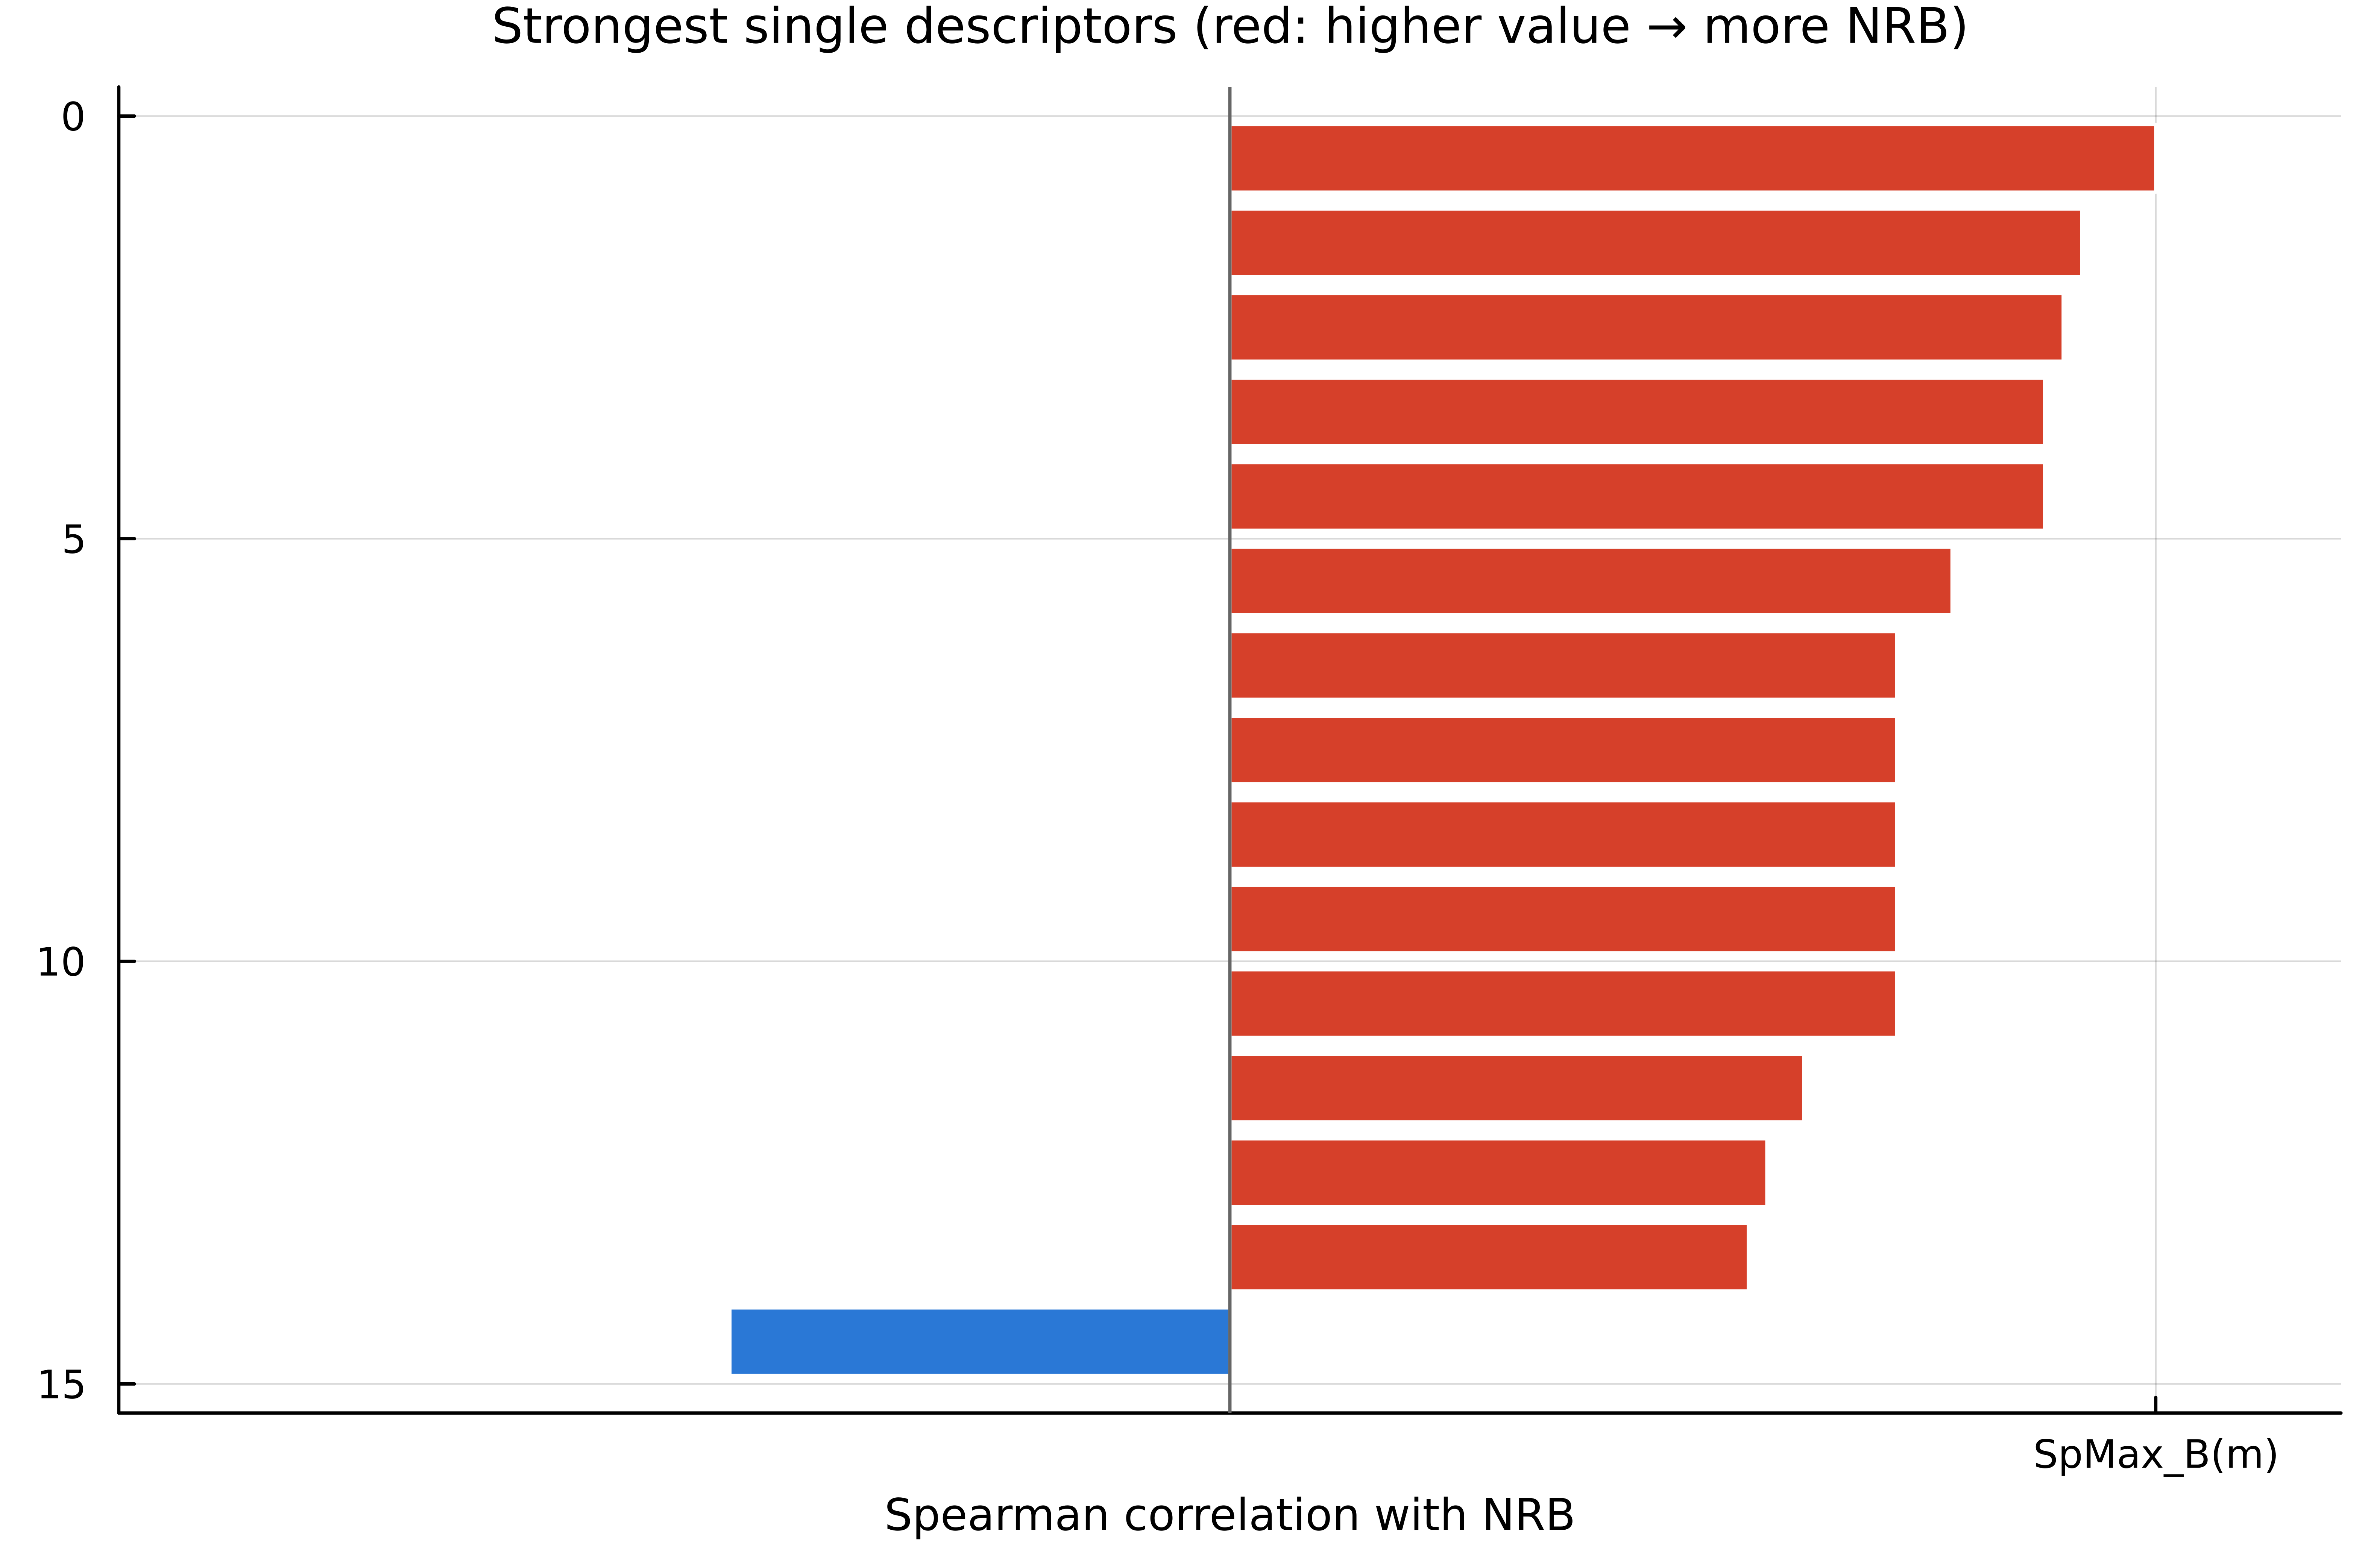

In [8]:
top = first(lab, 15)
fig2 = bar(top.descriptor, top.spearman_with_NRB; orientation = :h, yflip = true, legend = false,
           color = ifelse.(top.spearman_with_NRB .>= 0, POS_COLOR, NEG_COLOR), linecolor = :white,
           xlims = (-0.6, 0.6), size = (720, 470), xlabel = "Spearman correlation with NRB",
           title = "Strongest single descriptors (red: higher value → more NRB)")
vline!(fig2, [0]; color = :gray40, lw = 1)
savefig_(fig2, "01_descriptor_association.png")

> ### Insights
> - **17 pairs exceed |0.8|, forming 6 groups:** size/branching (SpMax_L, SpMax_A, SM6_L, SpMax_B(m), SM6_B(m), HyWi_B(m)); nitrogen (nN, F02[C-N], F03[C-N], F04[C-N]); composition (C%, Mi, SpPosA_B(p)); oxygen (nO, F03[C-O]); electronegativity (Me, Psi_i_A); bromine (B01[C-Br], B04[C-Br]). Each group is one property measured several ways.
> - **No descriptor is strong on its own:** the strongest, SpMax_B(m), has ρ = 0.50 with NRB, and the top six all come from the size/branching or composition groups. Larger, heavier, more branched molecules tend to be NRB.
> - **10 descriptors are zero for more than 85% of chemicals** and act as presence/absence flags for rare groups.
>
> **Consequences:** logistic regression weights within a group cannot be read one by one; tree splits and selected descriptors should be read as the group's property.

---
## 2. Stratified 5-fold folds

Each fold keeps the 66% NRB mix; identical descriptor rows always share a fold. Saved to `outputs/folds.csv` (one row per development chemical, in dev_row order: training rows, then validation rows).

In [10]:
row_key = [Tuple(r) for r in eachrow(X_dev)]
id_of   = Dict{Any,Int}()
grp     = [get!(id_of, k, length(id_of) + 1) for k in row_key]
fold = zeros(Int, nrow(D.dev))
rngf = MersenneTwister(FOLD_SEED)
for c in (0, 1)
    gids  = unique(grp[y_dev .== c]); shuffle!(rngf, gids)
    gsize = Dict(g => count(==(g), grp) for g in gids)
    sort!(gids, by = g -> -gsize[g], alg = MergeSort)
    load = zeros(Int, N_FOLDS)
    for g in gids
        f = argmin(load); fold[grp .== g] .= f; load[f] += gsize[g]
    end
end
@assert all(length(unique(fold[grp .== g])) == 1 for g in unique(grp))
CSV.write(joinpath(OUT_DIR, "folds.csv"), DataFrame(dev_row = 1:nrow(D.dev), class = D.ys_dev, fold = fold))
for f in 1:N_FOLDS
    println("fold $f: ", sum(fold .== f), " chemicals, NRB ", round(100 * mean(y_dev[fold .== f]), digits = 1), "%")
end

fold 1: 169 chemicals, NRB 66.3%
fold 2: 169 chemicals, NRB 66.3%
fold 3: 169 chemicals, NRB 66.3%
fold 4: 169 chemicals, NRB 66.3%
fold 5: 168 chemicals, NRB 66.1%


---
## 3. Descriptor lists: two selectors, inside each fold

Both selectors choose exactly k descriptors from descriptors standardized on the training part:

- **Regression selector (`reg`):** best-subset least squares on y = 0/1, as if predicting a number.
- **Logistic selector (`log`):** exact sparse logistic regression, which picks the descriptors that best *separate* RB from NRB.

For each fold the selector sees only that fold's 4 training folds, so the held-out fold never influences the choice. The final list (fold 0) is chosen on all 844 chemicals and used by the final models.

In [11]:
function select_descriptors(X, y, k, selector)
    mu, sd = standardize_fit(X, DESCRIPTORS)
    Z = DataFrame(zs(X, DESCRIPTORS, mu, sd), DESCRIPTORS)
    if selector == "reg"
        lnr = IAI.OptimalFeatureSelectionRegressor(sparsity = k, random_seed = SEED)
        IAI.fit!(lnr, Z, Float64.(y))
    else
        lnr = IAI.OptimalFeatureSelectionClassifier(sparsity = k, random_seed = SEED)
        IAI.fit!(lnr, Z, to_labels(y))
    end
    w = Dict(String(f) => b for (f, b) in IAI.get_prediction_weights(lnr)[1])
    [c for c in DESCRIPTORS if get(w, c, 0.0) != 0]
end

fs_rows = DataFrame(set = String[], fold = Int[], order = Int[], descriptor = String[])
for s in SETS
    s == "all" && continue
    for f in 0:N_FOLDS
        tr = f == 0 ? trues(length(y_dev)) : fold .!= f
        sel = select_descriptors(X_dev[tr, :], y_dev[tr], set_k(s), set_sel(s))
        for (i, c) in enumerate(sel)
            push!(fs_rows, (s, f, i, c))
        end
    end
    println(rpad(setlabel(s), 12), " final: ", join(fs_rows.descriptor[(fs_rows.set .== s) .& (fs_rows.fold .== 0)], ", "))
end
CSV.write(joinpath(OUT_DIR, "feature_sets.csv"), fs_rows)

[ Warning: This copy of Interpretable AI software is for academic purposes only and not for commercial use.


k=3 reg.     final: SpMax_L, LOC, SpPosA_B(p)
k=3 log.     final: SpMax_L, nHM, nN
k=5 reg.     final: SpMax_L, nO, LOC, nN, SM6_B(m)
k=5 log.     final: SpMax_L, nHM, nO, nN, SM6_B(m)
k=10 reg.    final: SpMax_L, C%, nO, HyWi_B(m), LOC, F03[C-O], nArNO2, SpPosA_B(p), nN, nArCOOR
k=10 log.    final: SpMax_L, nHM, NssssC, nO, LOC, nArNO2, Psi_i_A, nN, SM6_B(m), nArCOOR


"outputs\\feature_sets.csv"

**Stability.** For each budget and selector: how many folds chose each descriptor, and the mean overlap between fold lists (Jaccard: 1 = identical every time).

 Row │ k   selector             mean_jaccard  always_chosen                   final_list                                                                  
─────┼────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │  3  regression selector          0.48  SpMax_L                         SpMax_L, LOC, SpPosA_B(p)
   2 │  3  logistic selector            0.68  SpMax_L                         SpMax_L, nHM, nN
   3 │  5  regression selector          0.43  SpMax_L                         SpMax_L, nO, LOC, nN, SM6_B(m)
   4 │  5  logistic selector            0.6   SpMax_L                         SpMax_L, nHM, nO, nN, SM6_B(m)
   5 │ 10  regression selector          0.52  SpMax_L, HyWi_B(m), LOC         SpMax_L, C%, nO, HyWi_B(m), LOC, F03[C-O], nArNO2, SpPosA_B(p), nN, nArCOOR
   6 │ 10  logistic selector            0.62  SpMax_L, nHM, LOC, Psi_i_A, nN  SpMax_L, nHM, NssssC, nO, LOC, nArNO2, Ps

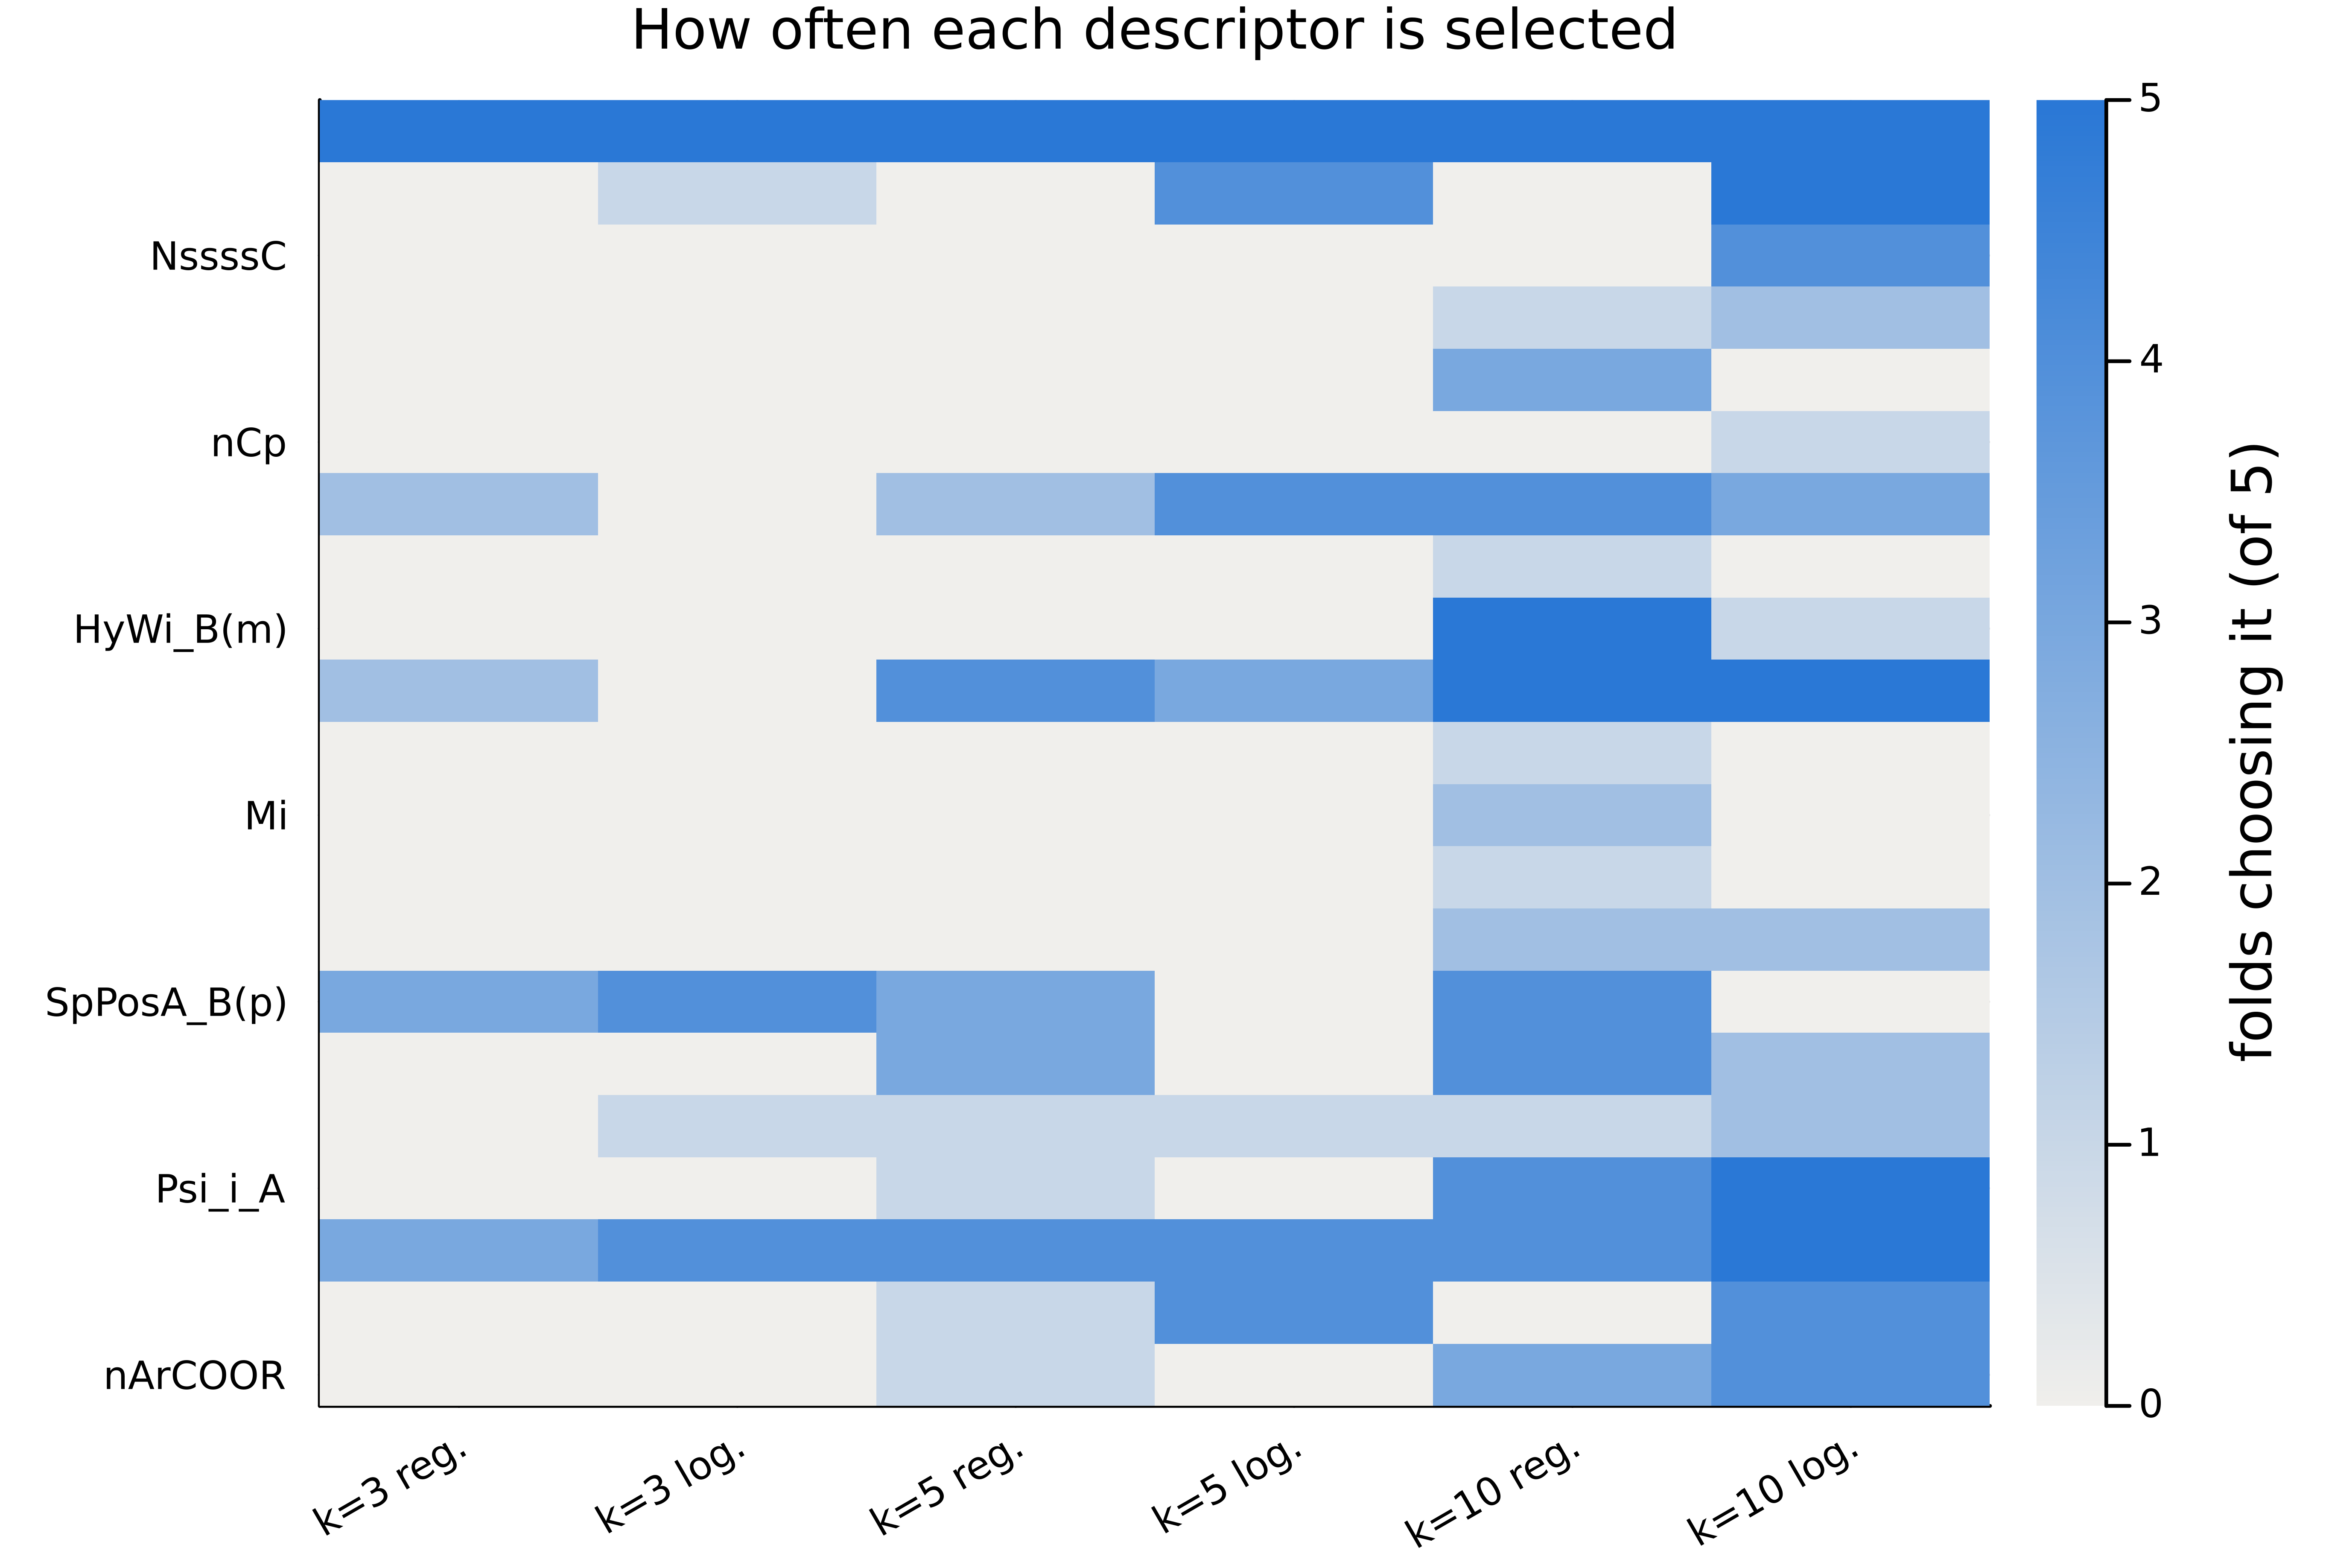

In [12]:
fold_feats, final_feats = load_feature_sets()
jaccard(a, b) = length(intersect(a, b)) / length(union(a, b))
stab = DataFrame(k = Int[], selector = String[], mean_jaccard = Float64[], always_chosen = String[], final_list = String[])
for s in SETS
    s == "all" && continue
    L = [fold_feats[(s, f)] for f in 1:N_FOLDS]
    push!(stab, (set_k(s), SEL_NAME[set_sel(s)], round(mean(jaccard(L[a], L[b]) for a in 1:N_FOLDS for b in a+1:N_FOLDS), digits = 2),
                 join([c for c in DESCRIPTORS if all(c in l for l in L)], ", "), join(final_feats[s], ", ")))
end
show(stab, allrows = true, allcols = true, eltypes = false, summary = false, truncate = 0)
CSV.write(joinpath(OUT_DIR, "selection_stability.csv"), stab)
println()

sel_sets = [s for s in SETS if s != "all"]
ever = [c for c in DESCRIPTORS if any(c in fold_feats[(s, f)] for s in sel_sets for f in 1:N_FOLDS)]
freq = [count(f -> c in fold_feats[(s, f)], 1:N_FOLDS) for c in ever, s in sel_sets]
fig3 = heatmap(setlabel.(sel_sets), ever, freq; c = cgrad([MID_COLOR, NEG_COLOR]), clims = (0, N_FOLDS), yflip = true,
               size = (620, 40 + 18 * length(ever)), xrotation = 30, tickfontsize = 7,
               colorbar_title = "folds choosing it (of $N_FOLDS)", title = "How often each descriptor is selected")
savefig_(fig3, "01_selection_frequency.png")

> ### Insights (from our run of the same procedure)
> - **The logistic selector picks heavy atoms (nHM) and nitrogen count (nN)** at k = 3 (SpMax_L, nHM, nN), where the regression selector picks abstract indices (SpMax_L, LOC, SpPosA_B(p)). Halogens and nitrogen groups are classic reasons chemicals persist.
> - **The logistic selector is more stable** at every budget (mean Jaccard 0.68 vs. 0.48 at k = 3, 0.60 vs. 0.43 at k = 5, 0.62 vs. 0.52 at k = 10), so its list is a more trustworthy explanation.
> - **Both keep SpMax_L in every fold:** size/branching is the most consistent signal.